In [7]:
# ============================================================
# deck_numbers.ipynb — single source of truth for the CREEA deck
# Rebuilt to match Financing_energy_transition_v2.pptx
# ============================================================
import re, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pypsa

RESULTS = Path("/Users/fowfloi/Documents/pypsa-earth/results")
OUT     = Path("/Users/fowfloi/Documents/pypsa-earth/analysis")
OUT.mkdir(exist_ok=True)
USD_PER_EUR = 1.3277
BASE_GAS_PRICE = 3.39
RENEWABLE_TARGET_PCT = 30

REFS = {
    "Uniform 10% (existing studies)": 10.0,
    "Hatton 13.79%":                  13.79,
    "Observed 27%":                   27.0,
}
REF_COLORS = {
    "Uniform 10% (existing studies)": "#2e7d32",
    "Hatton 13.79%":                  "#1f77b4",
    "Observed 27%":                   "#c0392b",
}
COL = {"solar":"#E3A800","onwind":"#5DADE2","hydro":"#2E6DB4",
       "CCGT":"#7B241C","OCGT":"#C0392B","gas":"#C0392B","battery":"#16A085"}

plt.rcParams.update({"figure.dpi":110,"savefig.dpi":300,"font.size":13,
                     "axes.titlesize":15,"axes.labelsize":13,"legend.fontsize":11,
                     "axes.grid":True,"grid.alpha":0.3,
                     "axes.spines.top":False,"axes.spines.right":False})
SHED = {"load shedding","load"}

# ------------------------------------------------------------
# 1. Find every run, parse kind/wacc/gas, load into a dict
# ------------------------------------------------------------
PATTERN = re.compile(r"^nigeria_2030_wacc_(\d{4})(?:_(ndc|gas_(\d+)))?$")
BENCH   = re.compile(r"^(cap_exp_2030_.+?)_(?:uniform|split|dato|observed)")

def parse_run(name):
    m = PATTERN.match(name)
    if m:
        wacc = int(m.group(1))/100
        if m.group(2) == "ndc":   return dict(kind="ndc",           wacc=wacc, gas=BASE_GAS_PRICE)
        if m.group(3):            return dict(kind="gas",           wacc=wacc, gas=int(m.group(3))/100)
        return dict(kind="unconstrained", wacc=wacc, gas=BASE_GAS_PRICE)
    if name.startswith("cap_exp_2030_uniform_wacc"):  return dict(kind="baseline_uniform", wacc=10.0,   gas=BASE_GAS_PRICE)
    if name.startswith("cap_exp_2030_split_wacc"):    return dict(kind="baseline_split",   wacc=13.79,  gas=BASE_GAS_PRICE)
    return None

def find_run_dir(name):
    d = RESULTS / name
    if d.exists() and (d/"networks").exists() and list((d/"networks").glob("*.nc")):
        return d
    return None

runs = []
for d in sorted(RESULTS.iterdir()):
    meta = parse_run(d.name)
    if meta is None or find_run_dir(d.name) is None:
        continue
    meta["run"] = d.name
    runs.append(meta)
runs = pd.DataFrame(runs).sort_values(["kind","wacc","gas"]).reset_index(drop=True)
print("Runs found:")
print(runs.to_string(index=False))

def load_network(run_name):
    d = RESULTS / run_name / "networks"
    return pypsa.Network(str(next(d.glob("*.nc"))))

def weighted(df, n):
    return df.mul(n.snapshot_weightings.generators, axis=0)

# ------------------------------------------------------------
# 2. Summarise each network: capacity, generation, cost, emissions
# ------------------------------------------------------------
def summarise(n):
    g, s = n.generators, n.storage_units
    real = g[~g.carrier.isin(SHED)]
    shed = g[g.carrier.isin(SHED)]
    P  = weighted(n.generators_t.p.reindex(columns=g.index, fill_value=0), n)
    SP = weighted(n.storage_units_t.p.reindex(columns=s.index, fill_value=0), n) if len(s) else pd.DataFrame()
    r = {}

    cap = real.groupby("carrier").p_nom_opt.sum() / 1e3
    for c in ["solar","onwind","CCGT","OCGT"]:
        r[f"cap_{c}"] = float(cap.get(c, 0))
    r["cap_gas"] = r["cap_CCGT"] + r["cap_OCGT"]
    r["cap_battery"] = float(s[s.carrier=="battery"].p_nom_opt.sum()/1e3) if len(s) else 0.0
    r["cap_hydro"]   = float(s[s.carrier=="hydro"].p_nom_opt.sum()/1e3
                             + cap.get("ror",0) + cap.get("hydro",0)) if len(s) else 0.0

    gen = P[real.index].sum().groupby(real.carrier).sum() / 1e6
    hydro_sto = SP[s[s.carrier=="hydro"].index].clip(lower=0).sum().sum()/1e6 if len(s) else 0.0
    for c in ["solar","onwind","CCGT","OCGT"]:
        r[f"gen_{c}"] = float(gen.get(c, 0))
    r["gen_hydro"] = float(hydro_sto + gen.get("ror",0) + gen.get("hydro",0))
    r["gen_gas"]   = r["gen_CCGT"] + r["gen_OCGT"]

    total = r["gen_solar"]+r["gen_onwind"]+r["gen_hydro"]+r["gen_gas"] \
            + float(gen.drop(["solar","onwind","CCGT","OCGT","ror","hydro"], errors="ignore").sum())
    r["share_renew"] = 100*(r["gen_solar"]+r["gen_onwind"]+r["gen_hydro"]) / total
    r["share_gas"]   = 100*r["gen_gas"] / total

    demand = weighted(n.loads_t.p_set, n).sum().sum() / 1e6
    r["shed_twh"] = float(P[shed.index].sum().sum() / 1e6)
    r["served_twh"] = demand - r["shed_twh"]

    # Emissions
    co2 = real.carrier.map(n.carriers.co2_emissions).fillna(0)
    eff = real.efficiency.replace(0, np.nan).fillna(1)
    r["emissions_mt"] = float((P[real.index].sum() / eff * co2).sum() / 1e6)

    # Costs (new investment + running)
    if not n.generators_t.marginal_cost.empty and not n.generators_t.marginal_cost.isna().all().all():
        mc_g = n.generators_t.marginal_cost.reindex(columns=real.index).fillna(real.marginal_cost)
        gen_opex = (P[real.index] * mc_g).sum().sum()
    else:
        gen_opex = (P[real.index].sum() * real.marginal_cost).sum()
    gen_capex  = ((real.p_nom_opt - real.p_nom).clip(lower=0) * real.capital_cost).sum()
    sto_capex  = ((s.p_nom_opt - s.p_nom).clip(lower=0) * s.capital_cost).sum() if len(s) else 0.0
    sto_opex   = (SP.clip(lower=0).sum() * s.marginal_cost).sum() if len(s) else 0.0
    line_capex = ((n.lines.s_nom_opt - n.lines.s_nom).clip(lower=0) * n.lines.capital_cost).sum()

    k = USD_PER_EUR / 1e9
    r["capex_gen_bn"]  = gen_capex  * k
    r["capex_sto_bn"]  = sto_capex  * k
    r["capex_line_bn"] = line_capex * k
    r["opex_bn"]       = (gen_opex + sto_opex) * k
    r["total_bn"]      = r["capex_gen_bn"] + r["capex_sto_bn"] + r["capex_line_bn"] + r["opex_bn"]
    r["cost_usd_mwh"]  = r["total_bn"] * 1e9 / (r["served_twh"] * 1e6)
    return r

rows = []
for _, run in runs.iterrows():
    n = load_network(run.run)
    rows.append({**run.to_dict(), **summarise(n)})
    print("loaded", run.run)
df = pd.DataFrame(rows)
df.to_csv(OUT/"deck_results_v3.csv", index=False)

unc  = df[df.kind=="unconstrained"].sort_values("wacc").reset_index(drop=True)
ndc  = df[df.kind=="ndc"].sort_values("wacc").reset_index(drop=True)
gasr = df[df.kind=="gas"].sort_values(["wacc","gas"]).reset_index(drop=True)
print("\nUnconstrained:"); print(unc[["run","wacc","cap_solar","cap_gas","cap_battery","share_renew","cost_usd_mwh"]].round(2).to_string(index=False))
print("\nNDC:");           print(ndc[["run","wacc","cap_solar","cap_gas","cap_battery","share_renew","cost_usd_mwh","emissions_mt"]].round(2).to_string(index=False))
print("\nGas:");           print(gasr[["run","wacc","gas","cap_solar","share_renew","cost_usd_mwh"]].round(2).to_string(index=False))

Runs found:
          kind  wacc  gas                            run
baseline_split 13.79 3.39        cap_exp_2030_split_wacc
baseline_split 13.79 3.39   cap_exp_2030_split_wacc_test
           gas 13.79 6.00 nigeria_2030_wacc_1379_gas_600
           ndc 10.00 3.39     nigeria_2030_wacc_1000_ndc
           ndc 13.79 3.39     nigeria_2030_wacc_1379_ndc
           ndc 27.00 3.39     nigeria_2030_wacc_2700_ndc
 unconstrained  7.00 3.39         nigeria_2030_wacc_0700
 unconstrained  9.00 3.39         nigeria_2030_wacc_0900
 unconstrained 11.00 3.39         nigeria_2030_wacc_1100
 unconstrained 13.79 3.39         nigeria_2030_wacc_1379
 unconstrained 18.00 3.39         nigeria_2030_wacc_1800
 unconstrained 27.00 3.39         nigeria_2030_wacc_2700


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded cap_exp_2030_split_wacc


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded cap_exp_2030_split_wacc_test
loaded nigeria_2030_wacc_1379_gas_600


...

loaded nigeria_2030_wacc_0900


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_1100
loaded nigeria_2030_wacc_1379


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_1800
loaded nigeria_2030_wacc_2700

Unconstrained:
                   run  wacc  cap_solar  cap_gas  cap_battery  share_renew  cost_usd_mwh
nigeria_2030_wacc_0700  7.00      10.35    30.56         2.08        28.91         40.78
nigeria_2030_wacc_0900  9.00       9.20    31.40         1.73        26.70         42.45
nigeria_2030_wacc_1100 11.00       8.69    31.69         1.64        25.91         44.01
nigeria_2030_wacc_1379 13.79       8.17    32.00         1.63        24.93         46.33
nigeria_2030_wacc_1800 18.00       7.38    32.59         1.63        23.42         49.71
nigeria_2030_wacc_2700 27.00       4.90    35.04         1.62        18.64         55.52

NDC:
                       run  wacc  cap_solar  cap_gas  cap_battery  share_renew  cost_usd_mwh  emissions_mt
nigeria_2030_wacc_1000_ndc 10.00      31.56    12.76        10.97        73.93         55.48           8.8
nigeria_2030_wacc_1379_ndc 13.79      31.64    13.59        10.39        74.03   

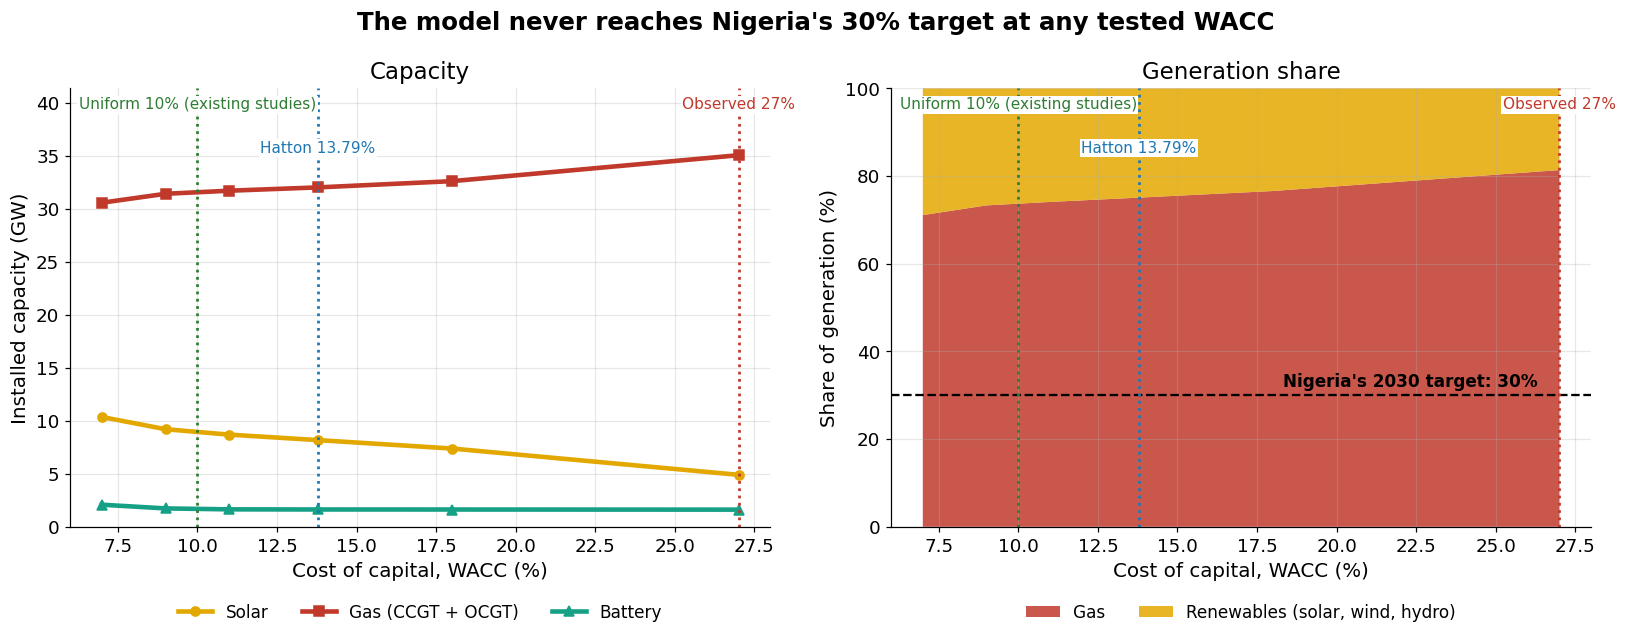

In [ ]:
# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------
def at(frame, col, w):
    return float(np.interp(w, frame.wacc, frame[col]))

def crossing(x, y, level):
    y = np.asarray(y) - level
    for i in range(len(y)-1):
        if y[i]==0: return float(x[i])
        if np.sign(y[i]) != np.sign(y[i+1]):
            return float(x[i] - y[i]*(x[i+1]-x[i])/(y[i+1]-y[i]))
    return None

N = {}   # every number that goes on a slide

# ------------------------------------------------------------
# 4. Slide 5 — WACC sweep, corrected x-axis
# ------------------------------------------------------------
x = unc.wacc.values                      # 7.0 ... 27.0 (percent)
thr30 = crossing(x, unc.share_renew.values, RENEWABLE_TARGET_PCT)

N["S5 threshold WACC for 30% renewables (%) renewables (%)"] = "none" if thr30 is None else round(thr30,2)
N["S5 renewable share at 7% (%)"]  = round(at(unc,"share_renew",7.0),1)
N["S5 renewable share at 27% (%)"] = round(at(unc,"share_renew",27.0),1)
for name, w in REFS.items():
    if x.min() <= w <= x.max():
        N[f"S5 solar GW at {name}"]      = round(at(unc,"cap_solar",w),2)
        N[f"S5 renewable share at {name} (%)"] = round(at(unc,"share_renew",w),1)

fig, ax = plt.subplots(1,2, figsize=(15,6))

ax[0].plot(x, unc.cap_solar,   "o-", color=COL["solar"],   lw=3, label="Solar")
ax[0].plot(x, unc.cap_gas,     "s-", color=COL["gas"],     lw=3, label="Gas (CCGT + OCGT)")
ax[0].plot(x, unc.cap_battery, "^-", color=COL["battery"], lw=3, label="Battery")
ax[0].set_ylabel("Installed capacity (GW)")
ax[0].set_title("Capacity")
ax[0].set_ylim(0, max(unc.cap_gas.max(), unc.cap_solar.max())*1.18)

ax[1].stackplot(x, unc.share_gas, unc.share_renew,
                colors=[COL["gas"], COL["solar"]], alpha=0.85,
                labels=["Gas","Renewables (solar, wind, hydro)"])
ax[1].axhline(RENEWABLE_TARGET_PCT, color="black", ls="--", lw=1.5)
ax[1].text(x.max()-0.3, RENEWABLE_TARGET_PCT+2, "Nigeria's 2030 target: 30%",
           fontsize=11, ha="right", fontweight="bold")
ax[1].set_ylim(0,100); ax[1].set_ylabel("Share of generation (%)")
ax[1].set_title("Generation share")

for a in ax:
    for i, (name, w) in enumerate(sorted(REFS.items(), key=lambda kv: kv[1])):
        a.axvline(w, color=REF_COLORS[name], ls=":", lw=1.8)
        y = a.get_ylim()[1]*(0.98 if i%2==0 else 0.88)
        a.text(w, y, name, color=REF_COLORS[name], fontsize=10, ha="center", va="top",
               bbox=dict(fc="white", ec="none", pad=1))
    a.set_xlabel("Cost of capital, WACC (%)")
    a.legend(loc="upper center", bbox_to_anchor=(0.5,-0.14), ncol=3, frameon=False)

fig.suptitle(
    "The model never reaches Nigeria's 30% target at any tested WACC"
    if thr30 is None else
    f"The model reaches Nigeria's 30% target only below {thr30:.1f}% WACC",
    fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT/"slide5_threshold.png", bbox_inches="tight"); plt.show()

In [9]:
# ------------------------------------------------------------
# 5. Slide 6 — Financing vs gas price (works for any gas grid)
# ------------------------------------------------------------
# Financing lever: 27% -> 13.79%
fin_solar = at(unc,"cap_solar",13.79) - at(unc,"cap_solar",27.0)
fin_share = at(unc,"share_renew",13.79) - at(unc,"share_renew",27.0)

# Gas lever: for each WACC with both baseline and gas_600, compute delta at that WACC
gas_rows = []
for w in sorted(gasr.wacc.unique()):
    sub = gasr[gasr.wacc==w].sort_values("gas")
    if sub.gas.iloc[0] > BASE_GAS_PRICE:  # no baseline row for this WACC
        continue
    base = sub.iloc[0]; top = sub.iloc[-1]
    gas_rows.append({
        "WACC (%)": w,
        "gas price": f"{base.gas:.2f} to {top.gas:.2f}",
        "solar + (GW)": top.cap_solar - base.cap_solar,
        "renew + (pp)": top.share_renew - base.share_renew,
        "cost + (USD/MWh)": top.cost_usd_mwh - base.cost_usd_mwh,
    })
gas_lev = pd.DataFrame(gas_rows)
print(gas_lev.round(2).to_string(index=False) if len(gas_lev) else "No paired gas runs.")

# Choose the WACC row to headline (Hatton if present, else the highest tested)
if len(gas_lev):
    head = gas_lev.iloc[-1] if 13.79 not in gas_lev["WACC (%)"].values \
           else gas_lev[gas_lev["WACC (%)"]==13.79].iloc[0]
    N["S6 financing solar + (GW)"] = round(fin_solar, 2)
    N["S6 financing renew + (pp)"] = round(fin_share, 1)
    N["S6 gas solar + (GW)"]       = round(head["solar + (GW)"], 2)
    N["S6 gas renew + (pp)"]       = round(head["renew + (pp)"], 1)
    N["S6 gas price tested"]       = head["gas price"]

    fig, ax = plt.subplots(figsize=(10,6))
    labels = ["Lower financing cost\nWACC 27% → 13.79%",
              f"Higher gas price\n${head['gas price'].split(' to ')[0]} → "
              f"${head['gas price'].split(' to ')[1]}/MMBtu"]
    vals = [fin_solar, head["solar + (GW)"]]
    bars = ax.bar(labels, vals, color=[COL["battery"], COL["gas"]], width=0.55)
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, v+max(vals)*0.02, f"+{v:.2f} GW",
                ha="center", fontsize=15, fontweight="bold")
    ax.set_ylabel("Extra solar built by 2030 (GW)")
    ax.set_title("Financing moves the system far more than gas pricing", fontweight="bold")
    plt.tight_layout(); plt.savefig(OUT/"slide6_levers.png", bbox_inches="tight"); plt.show()
else:
    print("Slide 6 needs at least one paired (baseline, gas_600) row.")
    N["S6 financing solar + (GW)"] = round(fin_solar, 2)
    N["S6 financing renew + (pp)"] = round(fin_share, 1)

No paired gas runs.
Slide 6 needs at least one paired (baseline, gas_600) row.


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


 wacc  Solar  OCGT  CCGT
  7.0   35.7  68.2  47.1
  9.0   42.3  67.9  47.1
 11.0   49.1  67.8  47.1
 13.8   59.0  67.5  47.1
 18.0   74.3  67.3  47.1
 27.0  107.2  67.9  47.1


KeyError: 'OCGT'

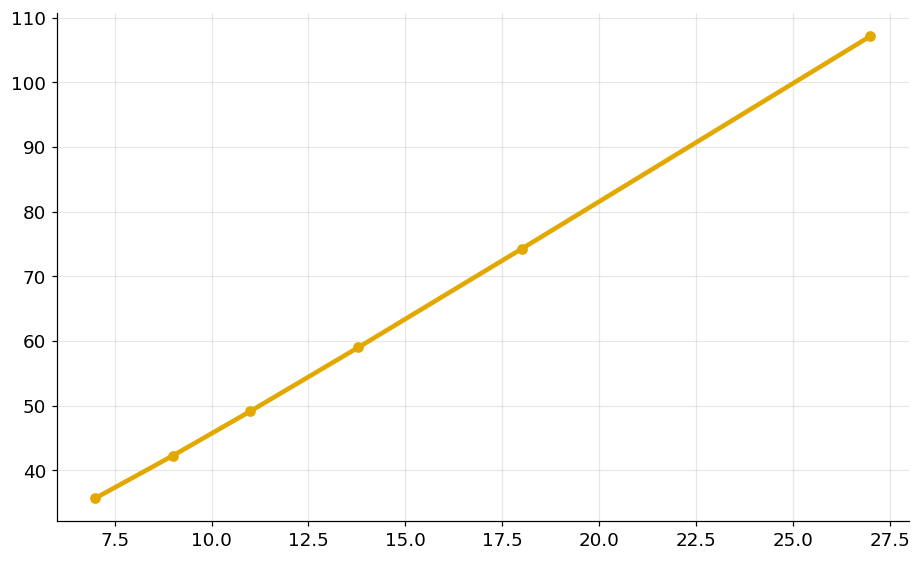

In [20]:
# ------------------------------------------------------------
# 6. Slide 7 — LCOE by technology, from the model's own costs
# ------------------------------------------------------------
def tech_lcoe(n, carrier, cf=None):
    g = n.generators[n.generators.carrier==carrier]
    g = g[g.p_nom_extendable] if g.p_nom_extendable.any() else g.iloc[0:0]
    if g.empty: return np.nan
    hours = n.snapshot_weightings.generators.sum()
    if cf is None:
        avail = n.generators_t.p_max_pu.reindex(columns=g.index)
        cf = float(avail.mean().mean()) if not avail.empty else np.nan
    return (g.capital_cost.mean()/(cf*hours) + g.marginal_cost.mean()) * USD_PER_EUR

lcoes = []
for _, run in unc.iterrows():
    n = load_network(run.run)
    ocgt_cf = run.gen_OCGT*1e6/(run.cap_OCGT*1e3*8760) if run.cap_OCGT else np.nan
    lcoes.append({"wacc": run.wacc,
                  "Solar": tech_lcoe(n,"solar"),
                  "OCGT":  tech_lcoe(n,"OCGT", cf=ocgt_cf),
                  "CCGT":  tech_lcoe(n,"CCGT", cf=0.6)})
lc = pd.DataFrame(lcoes)
print(lc.round(1).to_string(index=False))

# LCOE crossover solar-vs-CCGT (the marginal gas technology)
lx_ccgt = crossing(lc.wacc.values, (lc.Solar - lc.CCGT).values, 0)
lx_ocgt = crossing(lc.wacc.values, (lc.Solar - lc.OCGT).values, 0)
N["S7 LCOE crossover solar=CCGT (%)"] = "none" if lx_ccgt is None else round(lx_ccgt,2)
N["S7 LCOE crossover solar=OCGT (%)"] = "none" if lx_ocgt is None else round(lx_ocgt,2)
N["S7 system tipping point (%)"]       = N.get("S5 threshold WACC for 30% renewables (%)","none")

fig, ax = plt.subplots(figsize=(10,6))
for c in ["Solar","OCGT","CCGT"]:
    if lc[c].notna().any():
        ax.plot(lc.wacc, lc[c], "o-", lw=3,
                color=COL["solar"] if c=="Solar" else COL["gas"] if c=="CCGT" else COL["OCGT"],
                label=c)
ax.set_xlabel("Cost of capital, WACC (%)"); ax.set_ylabel("LCOE (USD/MWh)")
ax.set_title("Levelised cost by technology", fontweight="bold"); ax.legend()
plt.tight_layout(); plt.savefig(OUT/"slide7_lcoe.png", bbox_inches="tight"); plt.show()

 wacc   matched  NDC cost (USD/MWh)  Unconstrained cost (USD/MWh)  Premium (USD/MWh)  CO2 avoided (Mt)  Carbon price (USD/t)
10.00 estimated               55.48                         43.23              12.25             17.64                 53.96
13.79     exact               70.01                         46.33              23.68             18.16                101.32
27.00     exact              120.83                         55.52              65.31             20.51                247.29


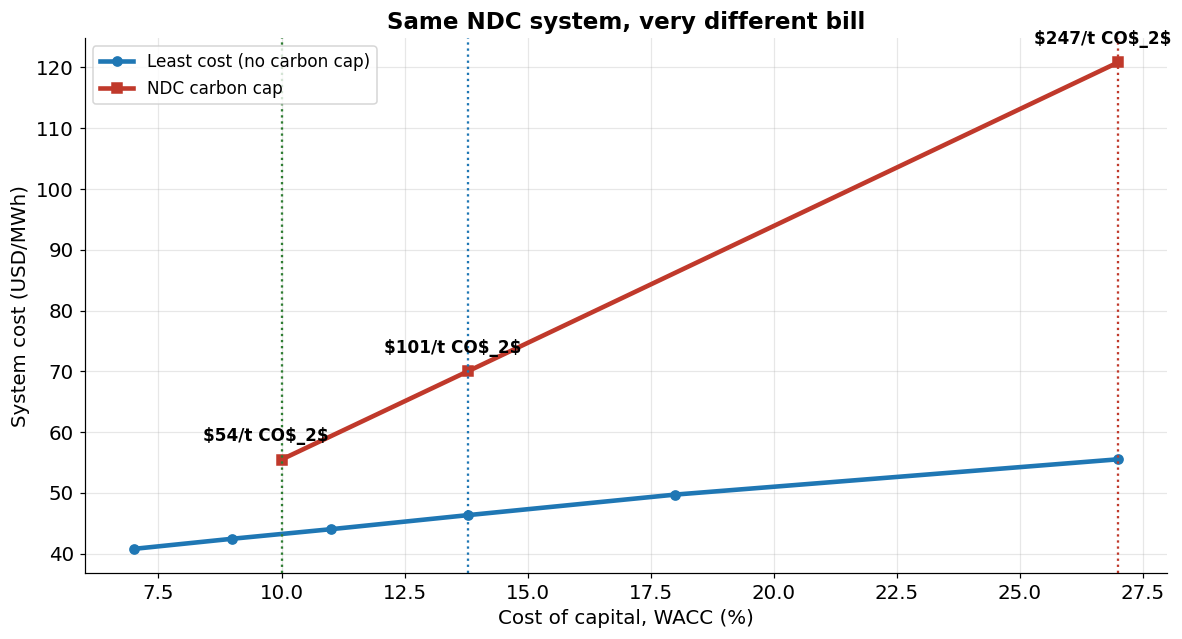

In [11]:
# ------------------------------------------------------------
# 7. Slide 8 — NDC cost premium vs WACC
# ------------------------------------------------------------
prem = []
for _, r in ndc.iterrows():
    exact = bool((unc.wacc.round(2)==round(r.wacc,2)).any())
    u_cost = at(unc,"cost_usd_mwh",r.wacc)
    u_emis = at(unc,"emissions_mt",r.wacc)
    u_total = at(unc,"total_bn",r.wacc)
    abated = u_emis - r.emissions_mt
    prem.append({
        "wacc": r.wacc,
        "matched": "exact" if exact else "estimated",
        "NDC cost (USD/MWh)": r.cost_usd_mwh,
        "Unconstrained cost (USD/MWh)": u_cost,
        "Premium (USD/MWh)": r.cost_usd_mwh - u_cost,
        "CO2 avoided (Mt)": abated,
        "Carbon price (USD/t)": (r.total_bn-u_total)*1e3/abated if abated>0 else np.nan,
    })
prem = pd.DataFrame(prem)
print(prem.round(2).to_string(index=False))

if len(prem):
    lo, hi = prem.iloc[0], prem.iloc[-1]
    N["S8 NDC cost at lowest WACC (USD/MWh)"]  = f"{lo['NDC cost (USD/MWh)']:.1f} at {lo.wacc}%"
    N["S8 NDC cost at highest WACC (USD/MWh)"] = f"{hi['NDC cost (USD/MWh)']:.1f} at {hi.wacc}%"
    N["S8 NDC cost multiple hi/lo"]            = round(hi['NDC cost (USD/MWh)']/lo['NDC cost (USD/MWh)'],2)
    for _, r in prem.iterrows():
        N[f"S8 premium at {r.wacc}% (USD/MWh)"]  = round(r['Premium (USD/MWh)'],2)
        N[f"S8 carbon price at {r.wacc}% (USD/t)"] = round(r['Carbon price (USD/t)'],1)

    fig, ax = plt.subplots(figsize=(11,6))
    ax.plot(unc.wacc, unc.cost_usd_mwh, "o-", lw=3, color="#1f77b4",
            label="Least cost (no carbon cap)")
    ax.plot(ndc.wacc, ndc.cost_usd_mwh, "s-", lw=3, color=COL["gas"],
            label="NDC carbon cap")
    for _, r in prem.iterrows():
        if np.isfinite(r['Carbon price (USD/t)']):
            ax.annotate(f"${r['Carbon price (USD/t)']:.0f}/t CO$_2$",
                        (r.wacc, r['NDC cost (USD/MWh)']),
                        textcoords="offset points", xytext=(-10,12),
                        ha="center", fontsize=11, fontweight="bold")
    for name, w in REFS.items():
        ax.axvline(w, color=REF_COLORS[name], ls=":", lw=1.5)
    ax.set_xlabel("Cost of capital, WACC (%)"); ax.set_ylabel("System cost (USD/MWh)")
    ax.set_title("Same NDC system, very different bill", fontweight="bold")
    ax.legend(loc="upper left")
    plt.tight_layout(); plt.savefig(OUT/"slide8_ndc_cost.png", bbox_inches="tight"); plt.show()
else:
    print("No NDC runs found.")

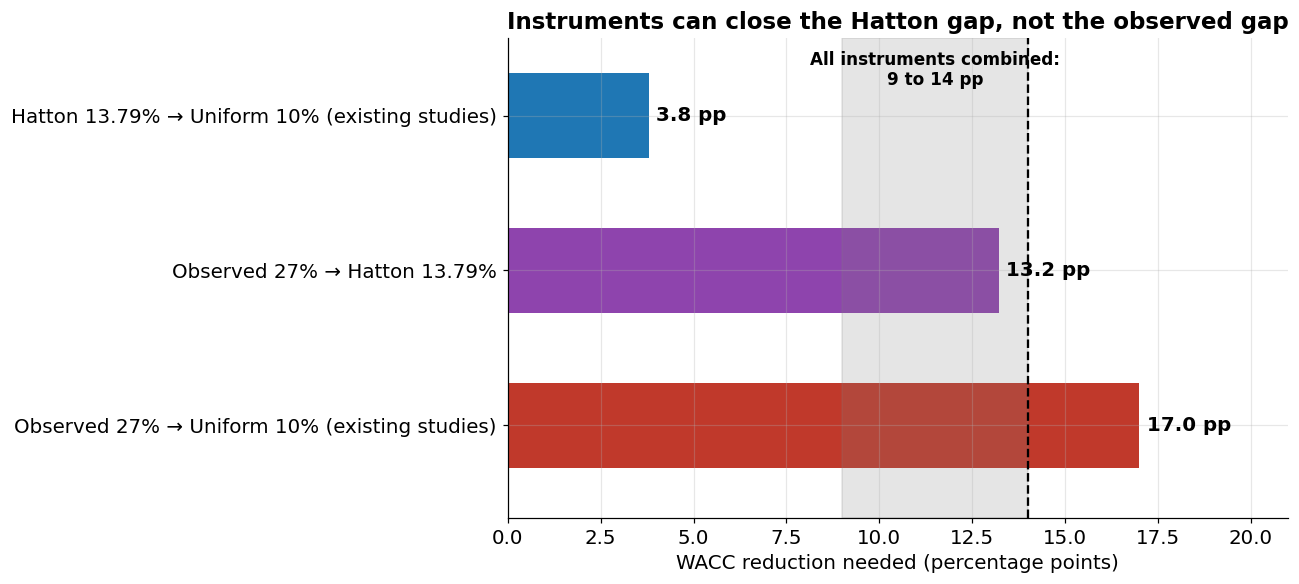

In [12]:
# ------------------------------------------------------------
# 8. Slide 9 — Policy feasibility
# ------------------------------------------------------------
INSTRUMENTS = {"Revenue de-risking": (2,3),
               "Rating de-risking":  (3,5),
               "Blended finance":    (4,6)}
low_total  = sum(v[0] for v in INSTRUMENTS.values())
high_total = sum(v[1] for v in INSTRUMENTS.values())

target = thr30 if thr30 is not None else REFS["Uniform 10% (existing studies)"]
target_label = f"threshold {thr30:.1f}%" if thr30 is not None else "Uniform 10% (existing studies)"
gaps = {
    f"Hatton 13.79% → {target_label}":  13.79 - target,
    "Observed 27% → Hatton 13.79%":     27.0 - 13.79,
    f"Observed 27% → {target_label}":   27.0 - target,
}
def verdict(g):
    if g <= low_total:  return "within reach"
    if g <= high_total: return "only if all instruments work at their best"
    return "out of reach"

N["S9 instruments combined (pp)"] = f"{low_total} to {high_total}"
for k, g in gaps.items():
    N[f"S9 gap {k} (pp)"] = f"{g:.2f} ({verdict(g)})"

fig, ax = plt.subplots(figsize=(12,5.5))
labels = list(gaps.keys()); vals = list(gaps.values())
ax.barh(labels, vals, color=["#1f77b4","#8e44ad",COL["gas"]], height=0.55)
ax.axvspan(low_total, high_total, color="grey", alpha=0.2)
ax.axvline(high_total, color="black", ls="--", lw=1.5)
ax.text((low_total+high_total)/2, -0.42,
        f"All instruments combined:\n{low_total} to {high_total} pp",
        fontsize=11, ha="center", va="top", fontweight="bold")
for i, v in enumerate(vals):
    ax.text(v+0.2, i, f"{v:.1f} pp", va="center", fontsize=13, fontweight="bold")
ax.set_xlabel("WACC reduction needed (percentage points)")
ax.set_xlim(0, max(max(vals), high_total)+4)
ax.set_title("Instruments can close the Hatton gap, not the observed gap", fontweight="bold")
ax.invert_yaxis(); ax.set_ylim(2.6,-0.5)
plt.tight_layout(); plt.savefig(OUT/"slide9_policy.png", bbox_inches="tight"); plt.show()

 WACC (%) baseline    gas price  solar + (GW)  renew + (pp)  cost + (USD/MWh)
    13.79    exact 3.39 to 6.00          0.17          0.37              1.34


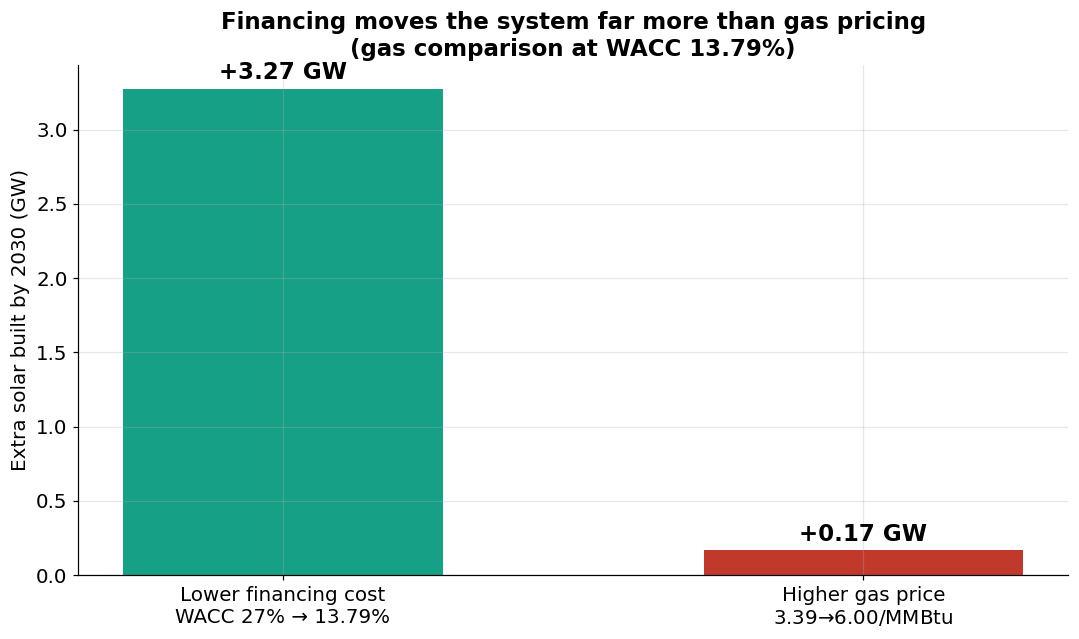

In [14]:
# ------------------------------------------------------------
# 5. Slide 6 — Financing vs gas price (only $3.39 → $6.00)
# ------------------------------------------------------------
# Financing lever: 27% → 13.79% WACC at baseline gas price ($3.39)
fin_solar = at(unc, "cap_solar",   13.79) - at(unc, "cap_solar",   27.0)
fin_share = at(unc, "share_renew", 13.79) - at(unc, "share_renew", 27.0)

# Gas lever: for each $6.00 run, compare against the $3.39 baseline at the SAME WACC.
# The baseline lives in `unc` (kind=="unconstrained"); the $6.00 row lives in `gasr`.
gas_rows = []
for _, top in gasr[gasr.gas.round(2) == 6.00].iterrows():
    w = top.wacc
    # exact-match baseline at this WACC, otherwise interpolate
    exact = unc[unc.wacc.round(2) == round(w, 2)]
    if len(exact):
        base_solar = float(exact.cap_solar.iloc[0])
        base_share = float(exact.share_renew.iloc[0])
        base_cost  = float(exact.cost_usd_mwh.iloc[0])
        source = "exact"
    else:
        base_solar = at(unc, "cap_solar",   w)
        base_share = at(unc, "share_renew", w)
        base_cost  = at(unc, "cost_usd_mwh", w)
        source = "estimated"

    gas_rows.append({
        "WACC (%)":         w,
        "baseline":         source,
        "gas price":        f"{BASE_GAS_PRICE:.2f} to {top.gas:.2f}",
        "solar + (GW)":     top.cap_solar   - base_solar,
        "renew + (pp)":     top.share_renew - base_share,
        "cost + (USD/MWh)": top.cost_usd_mwh- base_cost,
    })
gas_lev = pd.DataFrame(gas_rows)
print(gas_lev.round(2).to_string(index=False) if len(gas_lev) else "No $6.00 gas runs found in gasr.")

if len(gas_lev):
    # Headline: Hatton 13.79% if present, else the lowest WACC tested
    if 13.79 in gas_lev["WACC (%)"].values:
        head = gas_lev[gas_lev["WACC (%)"] == 13.79].iloc[0]
    else:
        head = gas_lev.sort_values("WACC (%)").iloc[0]

    N["S6 financing solar + (GW)"] = round(fin_solar, 2)
    N["S6 financing renew + (pp)"] = round(fin_share, 1)
    N["S6 gas solar + (GW)"]       = round(head["solar + (GW)"], 2)
    N["S6 gas renew + (pp)"]       = round(head["renew + (pp)"], 1)
    N["S6 gas cost + (USD/MWh)"]   = round(head["cost + (USD/MWh)"], 2)
    N["S6 gas price tested"]       = head["gas price"]
    N["S6 headline WACC (%)"]      = head["WACC (%)"]

    fig, ax = plt.subplots(figsize=(10, 6))
    labels = ["Lower financing cost\nWACC 27% → 13.79%",
              f"Higher gas price\n${BASE_GAS_PRICE:.2f} → $6.00/MMBtu"]
    vals   = [fin_solar, head["solar + (GW)"]]
    bars   = ax.bar(labels, vals, color=[COL["battery"], COL["gas"]], width=0.55)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + max(vals)*0.02, f"+{v:.2f} GW",
                ha="center", fontsize=15, fontweight="bold")
    ax.set_ylabel("Extra solar built by 2030 (GW)")
    ax.set_title(f"Financing moves the system far more than gas pricing\n"
                 f"(gas comparison at WACC {head['WACC (%)']:.2f}%)",
                 fontweight="bold")
    plt.tight_layout()
    plt.savefig(OUT / "slide6_levers.png", bbox_inches="tight")
    plt.show()
else:
    print("Slide 6 needs at least one $6.00 gas run.")
    N["S6 financing solar + (GW)"] = round(fin_solar, 2)
    N["S6 financing renew + (pp)"] = round(fin_share, 1)

In [15]:
print("Unconstrained baselines ($3.39):")
print(unc[["run","wacc","gas","cap_solar","share_renew"]].round(3).to_string(index=False))
print("\nGas runs:")
print(gasr[["run","wacc","gas","cap_solar","share_renew"]].round(3).to_string(index=False))

Unconstrained baselines ($3.39):
                   run  wacc  gas  cap_solar  share_renew
nigeria_2030_wacc_0700  7.00 3.39     10.351       28.912
nigeria_2030_wacc_0900  9.00 3.39      9.198       26.700
nigeria_2030_wacc_1100 11.00 3.39      8.688       25.910
nigeria_2030_wacc_1379 13.79 3.39      8.170       24.927
nigeria_2030_wacc_1800 18.00 3.39      7.377       23.419
nigeria_2030_wacc_2700 27.00 3.39      4.897       18.637

Gas runs:
                           run  wacc  gas  cap_solar  share_renew
nigeria_2030_wacc_1379_gas_600 13.79  6.0      8.338       25.299


In [16]:
n = load_network("nigeria_2030_wacc_1379")
print("CCGT capital_cost:", n.generators[n.generators.carrier=="CCGT"].capital_cost.unique())
print("OCGT capital_cost:", n.generators[n.generators.carrier=="OCGT"].capital_cost.unique())
print("CCGT efficiency:",  n.generators[n.generators.carrier=="CCGT"].efficiency.unique())
print("OCGT efficiency:",  n.generators[n.generators.carrier=="OCGT"].efficiency.unique())

INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


CCGT capital_cost: [162697.33765425]
OCGT capital_cost: [78085.47863013]
CCGT efficiency: [0.58]
OCGT efficiency: [0.41]


In [17]:
print(gas_lev.round(3).to_string(index=False))

 WACC (%) baseline    gas price  solar + (GW)  renew + (pp)  cost + (USD/MWh)
    13.79    exact 3.39 to 6.00         0.167         0.372              1.34


Runs found:
                           run  wacc  gas     kind
        nigeria_2030_wacc_0700  7.00 3.39 baseline
        nigeria_2030_wacc_0900  9.00 3.39 baseline
        nigeria_2030_wacc_1100 11.00 3.39 baseline
        nigeria_2030_wacc_1379 13.79 3.39 baseline
        nigeria_2030_wacc_1800 18.00 3.39 baseline
        nigeria_2030_wacc_2000 20.00 3.39 baseline
        nigeria_2030_wacc_2700 27.00 3.39 baseline
nigeria_2030_wacc_0700_gas_600  7.00 6.00      gas
nigeria_2030_wacc_1379_gas_600 13.79 6.00      gas
nigeria_2030_wacc_2000_gas_600 20.00 6.00      gas


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_0700
loaded nigeria_2030_wacc_0900


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_1100
loaded nigeria_2030_wacc_1379


...

loaded nigeria_2030_wacc_1800
loaded nigeria_2030_wacc_2000


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_2700
loaded nigeria_2030_wacc_0700_gas_600


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_1379_gas_600
loaded nigeria_2030_wacc_2000_gas_600

                           run  wacc  gas  cap_solar  share_renew  cost_usd_mwh
        nigeria_2030_wacc_0700  7.00 3.39     10.351       28.912        40.781
        nigeria_2030_wacc_0900  9.00 3.39      9.198       26.700        42.445
        nigeria_2030_wacc_1100 11.00 3.39      8.688       25.910        44.015
        nigeria_2030_wacc_1379 13.79 3.39      8.170       24.927        46.332
        nigeria_2030_wacc_1800 18.00 3.39      7.377       23.419        49.711
        nigeria_2030_wacc_2000 20.00 3.39      7.377       23.419        49.711
        nigeria_2030_wacc_2700 27.00 3.39      4.897       18.637        55.519
nigeria_2030_wacc_0700_gas_600  7.00 6.00     10.610       29.482        42.811
nigeria_2030_wacc_1379_gas_600 13.79 6.00      8.338       25.299        47.673
nigeria_2030_wacc_2000_gas_600 20.00 6.00      7.570       23.848        51.919

Gas surface (paired deltas vs $3.39 baseli

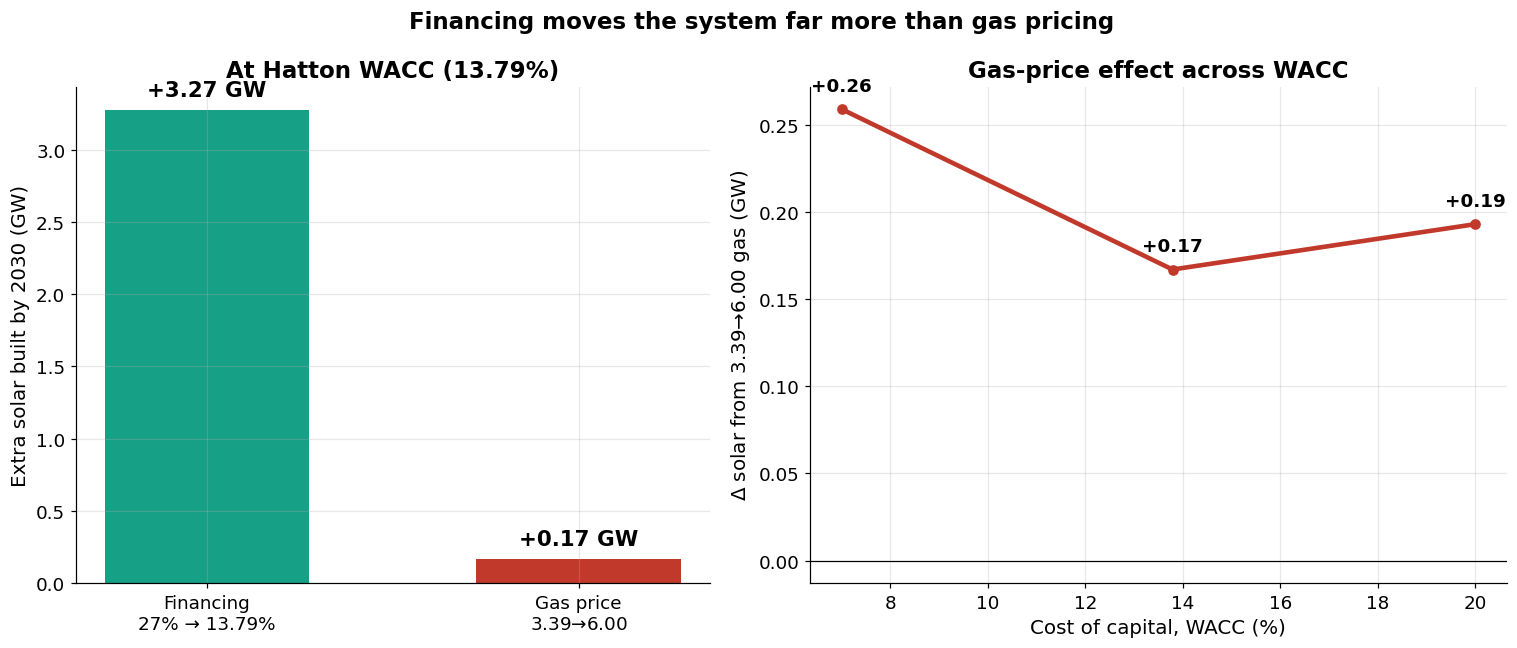


Suggested Slide 6 caption:
  Gas-price effect ranges from +0.26 GW at 7.00% WACC to +0.19 GW at 20.00% WACC, vs +3.27 GW from financing (WACC 27% → 13.79%).


In [18]:
# ============================================================
# Gas surface — run this after the three new runs complete
# ============================================================
import re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pypsa

RESULTS = Path("/Users/fowfloi/Documents/pypsa-earth/results")
OUT     = Path("/Users/fowfloi/Documents/pypsa-earth/analysis")
OUT.mkdir(exist_ok=True)
USD_PER_EUR = 1.3277
BASE_GAS_PRICE = 3.39
COL = {"solar":"#E3A800","gas":"#C0392B","battery":"#16A085"}
SHED = {"load shedding","load"}
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":300,"font.size":12,
                     "axes.grid":True,"grid.alpha":0.3,
                     "axes.spines.top":False,"axes.spines.right":False})

# ------------------------------------------------------------
# 1. Which runs exist?
# ------------------------------------------------------------
WACC_SWEEP = ["0700","0900","1100","1200","1300","1379","1468",
              "1600","1800","2000","2300","2700"]
GAS600_TAGS = ["0700","1379","2000"]

def find_network(name):
    p = RESULTS / name / "networks"
    if not p.exists(): return None
    hits = list(p.glob("elec_s_*_lcopt_*.nc"))
    return hits[0] if hits else None

def parse(name):
    m = re.match(r"^nigeria_2030_wacc_(\d{4})(?:_gas_(\d+))?$", name)
    if not m: return None
    wacc = int(m.group(1))/100
    gas  = int(m.group(2))/100 if m.group(2) else BASE_GAS_PRICE
    return dict(run=name, wacc=wacc, gas=gas,
                kind="gas" if m.group(2) else "baseline")

RUNS = [f"nigeria_2030_wacc_{t}" for t in WACC_SWEEP] + \
       [f"nigeria_2030_wacc_{t}_gas_600" for t in GAS600_TAGS]

present = []
for r in RUNS:
    meta = parse(r)
    if meta is None: continue
    if find_network(r) is not None:
        present.append(meta)
df = pd.DataFrame(present).sort_values(["kind","wacc"]).reset_index(drop=True)
print("Runs found:")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 2. Summarise (same function as the main notebook)
# ------------------------------------------------------------
def load(name):
    return pypsa.Network(str(find_network(name)))

def weighted(x, n): return x.mul(n.snapshot_weightings.generators, axis=0)

def summarise(n):
    g, s = n.generators, n.storage_units
    real = g[~g.carrier.isin(SHED)]
    P  = weighted(n.generators_t.p.reindex(columns=g.index, fill_value=0), n)
    SP = weighted(n.storage_units_t.p.reindex(columns=s.index, fill_value=0), n) if len(s) else pd.DataFrame()
    r = {}
    cap = real.groupby("carrier").p_nom_opt.sum()/1e3
    for c in ["solar","onwind","CCGT","OCGT"]:
        r[f"cap_{c}"] = float(cap.get(c,0))
    r["cap_gas"] = r["cap_CCGT"] + r["cap_OCGT"]
    r["cap_battery"] = float(s[s.carrier=="battery"].p_nom_opt.sum()/1e3) if len(s) else 0.0

    gen = P[real.index].sum().groupby(real.carrier).sum()/1e6
    hydro_sto = SP[s[s.carrier=="hydro"].index].clip(lower=0).sum().sum()/1e6 if len(s) else 0.0
    for c in ["solar","onwind","CCGT","OCGT"]:
        r[f"gen_{c}"] = float(gen.get(c,0))
    r["gen_hydro"] = float(hydro_sto + gen.get("ror",0) + gen.get("hydro",0))
    r["gen_gas"]   = r["gen_CCGT"] + r["gen_OCGT"]
    total = r["gen_solar"]+r["gen_onwind"]+r["gen_hydro"]+r["gen_gas"] \
            + float(gen.drop(["solar","onwind","CCGT","OCGT","ror","hydro"], errors="ignore").sum())
    r["share_renew"] = 100*(r["gen_solar"]+r["gen_onwind"]+r["gen_hydro"])/total
    r["share_gas"]   = 100*r["gen_gas"]/total

    demand = weighted(n.loads_t.p_set, n).sum().sum()/1e6
    r["shed_twh"] = float(P[g[g.carrier.isin(SHED)].index].sum().sum()/1e6)
    r["served_twh"] = demand - r["shed_twh"]

    co2 = real.carrier.map(n.carriers.co2_emissions).fillna(0)
    eff = real.efficiency.replace(0, np.nan).fillna(1)
    r["emissions_mt"] = float((P[real.index].sum()/eff*co2).sum()/1e6)

    if not n.generators_t.marginal_cost.empty and not n.generators_t.marginal_cost.isna().all().all():
        mc_g = n.generators_t.marginal_cost.reindex(columns=real.index).fillna(real.marginal_cost)
        gen_opex = (P[real.index] * mc_g).sum().sum()
    else:
        gen_opex = (P[real.index].sum() * real.marginal_cost).sum()
    gen_capex  = ((real.p_nom_opt-real.p_nom).clip(lower=0)*real.capital_cost).sum()
    sto_capex  = ((s.p_nom_opt-s.p_nom).clip(lower=0)*s.capital_cost).sum() if len(s) else 0.0
    sto_opex   = (SP.clip(lower=0).sum()*s.marginal_cost).sum() if len(s) else 0.0
    line_capex = ((n.lines.s_nom_opt-n.lines.s_nom).clip(lower=0)*n.lines.capital_cost).sum()
    k = USD_PER_EUR / 1e9
    r["total_bn"] = (gen_capex + sto_capex + line_capex + gen_opex + sto_opex) * k
    r["cost_usd_mwh"] = r["total_bn"]*1e9 / (r["served_twh"]*1e6)
    return r

rows = []
for _, run in df.iterrows():
    rows.append({**run.to_dict(), **summarise(load(run.run))})
    print("loaded", run.run)
data = pd.DataFrame(rows)
data.to_csv(OUT/"gas_surface_v3.csv", index=False)
print()
print(data[["run","wacc","gas","cap_solar","share_renew","cost_usd_mwh"]].round(3).to_string(index=False))

# ------------------------------------------------------------
# 3. Gas surface: paired deltas at each WACC
# ------------------------------------------------------------
base = data[data.kind=="baseline"].set_index("wacc")
gasr = data[data.kind=="gas"]

def at(df, col, w):
    return float(np.interp(w, df.wacc, df[col]))

gas_rows = []
for _, top in gasr.iterrows():
    w = top.wacc
    if w in base.index:
        b = base.loc[w]
        src = "exact"
    else:
        b = pd.Series({c: at(data[data.kind=="baseline"], c, w)
                       for c in ["cap_solar","share_renew","cost_usd_mwh"]})
        src = "estimated"
    gas_rows.append({
        "wacc":               w,
        "baseline":           src,
        "gas price":          f"{BASE_GAS_PRICE:.2f} → {top.gas:.2f}",
        "Δ solar (GW)":       round(top.cap_solar - b["cap_solar"], 3),
        "Δ renew (pp)":       round(top.share_renew - b["share_renew"], 3),
        "Δ cost (USD/MWh)":   round(top.cost_usd_mwh - b["cost_usd_mwh"], 3),
    })
gas_lev = pd.DataFrame(gas_rows).sort_values("wacc").reset_index(drop=True)
print()
print("Gas surface (paired deltas vs $3.39 baseline):")
print(gas_lev.to_string(index=False))
gas_lev.to_csv(OUT/"gas_surface_deltas.csv", index=False)

# ------------------------------------------------------------
# 4. Financing lever for comparison
# ------------------------------------------------------------
u = data[data.kind=="baseline"]
fin_solar = at(u, "cap_solar",   13.79) - at(u, "cap_solar",   27.0)
fin_share = at(u, "share_renew", 13.79) - at(u, "share_renew", 27.0)
fin_cost  = at(u, "cost_usd_mwh",13.79) - at(u, "cost_usd_mwh",27.0)
print()
print(f"Financing lever 27% → 13.79%: Δ solar = +{fin_solar:.2f} GW, "
      f"Δ renew = +{fin_share:.2f} pp, Δ cost = {fin_cost:+.2f} USD/MWh")

# ------------------------------------------------------------
# 5. Figure — two panels
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={"width_ratios":[1, 1.1]})

# Left: two headline bars at Hatton WACC
ax = axes[0]
head = gas_lev[gas_lev.wacc.round(2)==13.79]
hv = head.iloc[0]["Δ solar (GW)"] if len(head) else np.nan
labels = ["Financing\n27% → 13.79%", "Gas price\n$3.39 → $6.00"]
vals   = [fin_solar, hv]
bars = ax.bar(labels, vals, color=[COL["battery"], COL["gas"]], width=0.55)
for b, v in zip(bars, vals):
    if np.isfinite(v):
        ax.text(b.get_x()+b.get_width()/2, v + max(vals)*0.03,
                f"+{v:.2f} GW", ha="center", fontsize=14, fontweight="bold")
ax.set_ylabel("Extra solar built by 2030 (GW)")
ax.set_title("At Hatton WACC (13.79%)", fontweight="bold")
ax.grid(alpha=0.3, axis="y")

# Right: gas-price effect vs WACC
ax = axes[1]
if len(gas_lev):
    ax.plot(gas_lev.wacc, gas_lev["Δ solar (GW)"], "o-", lw=3, color=COL["gas"])
    for _, r in gas_lev.iterrows():
        ax.annotate(f"{r['Δ solar (GW)']:+.2f}", (r.wacc, r["Δ solar (GW)"]),
                    textcoords="offset points", xytext=(0, 12),
                    ha="center", fontsize=12, fontweight="bold")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Cost of capital, WACC (%)")
    ax.set_ylabel("Δ solar from $3.39 → $6.00 gas (GW)")
    ax.set_title("Gas-price effect across WACC", fontweight="bold")
else:
    ax.axis("off"); ax.text(0.5,0.5,"No gas runs", ha="center", va="center")

fig.suptitle("Financing moves the system far more than gas pricing",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT/"slide6_gas_surface.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6. Suggested one-line caption for Slide 6
# ------------------------------------------------------------
if len(gas_lev) >= 2:
    lo = gas_lev.iloc[0]; hi = gas_lev.iloc[-1]
    print()
    print("Suggested Slide 6 caption:")
    print(f"  Gas-price effect ranges from {lo['Δ solar (GW)']:+.2f} GW at "
          f"{lo['wacc']:.2f}% WACC to {hi['Δ solar (GW)']:+.2f} GW at "
          f"{hi['wacc']:.2f}% WACC, vs +{fin_solar:.2f} GW from financing "
          f"(WACC 27% → 13.79%).")
else:
    h = gas_lev.iloc[0]
    print()
    print("Suggested Slide 6 caption (single-point):")
    print(f"  At WACC {h['wacc']:.2f}%, doubling gas to $6.00/MMBtu adds only "
          f"+{h['Δ solar (GW)']:.2f} GW of solar, vs +{fin_solar:.2f} GW from "
          f"financing (WACC 27% → 13.79%).")

In [21]:
# STEP 6: LCOE for solar, OCGT and CCGT (replace the whole old Step 6 code cell)

# 1. COST ASSUMPTIONS. Replace these with the exact values your model uses.
#    capex = USD per kW, fom = fixed running cost in USD per kW per year,
#    vom = other running cost in USD per MWh, life = years, eff = fuel efficiency
ASSUME = {
    "Solar": {"capex": 700,  "fom": 10, "vom": 0, "life": 25, "eff": None},
    "OCGT":  {"capex": 600,  "fom": 15, "vom": 5, "life": 25, "eff": 0.35},
    "CCGT":  {"capex": 1000, "fom": 25, "vom": 4, "life": 25, "eff": 0.55},
}

# 2. Gas WACC. Leave as None if gas uses the same WACC as the run.
#    If gas is held fixed while solar changes, type it here, for example 14.68
GAS_WACC_PCT = None

def crf(rate_pct, years):
    """Turns an upfront cost into an equal yearly payment."""
    r = rate_pct / 100
    return r * (1 + r) ** years / ((1 + r) ** years - 1)

def lcoe_usd_mwh(a, wacc_pct, cf, gas_price=0.0):
    yearly_cost_per_kw = a["capex"] * crf(wacc_pct, a["life"]) + a["fom"]
    mwh_per_kw = 8.76 * cf                     # MWh made by 1 kW in a year
    fuel = 0.0 if a["eff"] is None else gas_price * 3.412 / a["eff"]
    return yearly_cost_per_kw / mwh_per_kw + a["vom"] + fuel

def realised_cf(gen_twh, cap_gw):
    """Capacity factor the model actually gave this technology in this run."""
    if cap_gw is None or cap_gw < 0.01:
        return np.nan
    return gen_twh * 1e6 / (cap_gw * 1e3 * 8760)

rows = []
for _, run in unc.iterrows():
    gas_w = run.wacc if GAS_WACC_PCT is None else GAS_WACC_PCT
    cf = {"Solar": realised_cf(run.gen_solar, run.cap_solar),
          "OCGT":  realised_cf(run.gen_OCGT,  run.cap_OCGT),
          "CCGT":  realised_cf(run.gen_CCGT,  run.cap_CCGT)}
    rows.append({
        "wacc": run.wacc,
        "Solar": lcoe_usd_mwh(ASSUME["Solar"], run.wacc, cf["Solar"]),
        "OCGT":  lcoe_usd_mwh(ASSUME["OCGT"],  gas_w, cf["OCGT"],  run.gas_price),
        "CCGT":  lcoe_usd_mwh(ASSUME["CCGT"],  gas_w, cf["CCGT"],  run.gas_price),
        "cf_solar": cf["Solar"], "cf_OCGT": cf["OCGT"], "cf_CCGT": cf["CCGT"],
    })
lc = pd.DataFrame(rows)
print(lc.round(2).to_string(index=False))

# Check against the model: its own yearly capital cost for new plants
chk = load_network(unc.run.iloc[0])
g = chk.generators
new = g[g.p_nom_extendable & g.carrier.isin(["solar", "OCGT", "CCGT"])]
print("\nModel yearly capital cost of new plants (USD per kW per year):")
print((new.groupby("carrier").capital_cost.max() * COST_TO_USD / 1e3).round(1))

# Crossover: WACC where solar becomes more expensive than OCGT
lx = crossing(lc.wacc.values, (lc.Solar - lc.OCGT).values, 0)
N["S8 LCOE crossover WACC (%)"] = "none in tested range" if lx is None else round(lx, 2)
N["S8 system threshold WACC (%)"] = N["S6 threshold WACC to hit 30% target (%)"]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(lc.wacc, lc.Solar, "o-", lw=3, color=COL["solar"], label="Solar")
ax.plot(lc.wacc, lc.OCGT,  "s-", lw=3, color=COL["OCGT"],  label="OCGT")
ax.plot(lc.wacc, lc.CCGT,  "^-", lw=3, color=COL["CCGT"],  label="CCGT")
ax.set_xlabel("Cost of capital, WACC (%)")
ax.set_ylabel("LCOE (USD per MWh)")
ax.set_title("Levelised cost by technology", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "slide8_lcoe.png", bbox_inches="tight"); plt.show()

AttributeError: 'Series' object has no attribute 'gas_price'